# EDA: text-only subreddits, all years

Exploratory analysis of the dataset that `extract_subreddits.py` builds
([`zachnorton03/textonly-subreddit-predictors`](https://huggingface.co/datasets/zachnorton03/textonly-subreddit-predictors)):
**every** submission from seven text subreddits, from the start of each subreddit to 2026-02.

Subreddits: AskReddit, Showerthoughts, unpopularopinion, dadjokes, hypotheticalsituation, sysadmin, TwoSentenceHorror.

Differences from the first EDA (`eda.ipynb`, a sample of all of Reddit in 2025):
- **All shards, not a sample.** Post counts by month, weekday, and hour are real Reddit activity now.
- **NSFW and deleted/removed posts were dropped by the extract** (same rules as `reddit_data.py`).
- **Times are local** (`America/New_York`), which also removes the daylight-saving shift in UTC.
- **Labels are relative to the subreddit and the time period** (`textonly_data.add_labels`): a post is a
  success if its engagement is above the 90th percentile of its subreddit in the same quarter.
- New sections: data gaps, score maturity by year, threshold drift, posting competition, edit notes that
  leak the outcome, reposts, and author history.

The source archive has **no posts from 2022-09 to 2023-11**. Charts shade this gap.

Shared definitions (derived columns, history features, labels) are in `textonly_data.py`.

In [1]:
import math

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

import textonly_data as td

td.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 100)

SOURCE = "local"  # "local" (data/textonly) or "hf" (read from the Hugging Face dataset)
LABEL = dict(metric="engagement", quantile=0.9, period="quarter", min_posts=100, self_only=True)
PANDAS_SAMPLE_PER_SUB = 200_000

SUBS, COLORS = td.SUBREDDITS, td.COLORS
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
# Diverging scale for "above / below the subreddit's own rate": orange below, neutral gray, blue above
DIVERGING = LinearSegmentedColormap.from_list("div", [td.ORANGE, "#f0efec", td.BLUE])

con = td.connect(SOURCE)
td.add_labels(con, **LABEL)
q = lambda sql: con.execute(sql).df()


def panels(n=len(SUBS), ncols=4, height=2.9, **kw):
    """Small multiples, one panel per subreddit. Returns (fig, list of axes); unused axes are hidden."""
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, height * nrows), layout="constrained", **kw)
    axes = list(np.ravel(axes))
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]


def shade_gap(ax):
    ax.axvspan(pd.Timestamp(td.GAP_START), pd.Timestamp(td.GAP_END), color="#e4e3df", alpha=0.6, linewidth=0)


def pct_axis(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

In [2]:
# Labeled text posts with the title but not the body. Built once so later queries are fast.
con.execute("""
CREATE OR REPLACE TABLE eda AS
SELECT id, subreddit, author, title, created_at, year, period, local_hour, local_dow, local_month,
       score, num_comments, score_metric, comments_metric, engagement, metric, threshold, label,
       title_length, title_words, title_has_question, title_has_number, title_all_caps,
       body_length, has_body, body_has_url, body_has_edit, has_link_flair, has_author_flair,
       posts_prev_hour, posts_prev_day, author_prev_posts, title_prev_count
FROM labeled
""")
con.execute(f"""
CREATE OR REPLACE TABLE eda_sample AS
SELECT * FROM eda
QUALIFY row_number() OVER (PARTITION BY subreddit ORDER BY hash(id)) <= {PANDAS_SAMPLE_PER_SUB}
""")
print(f"eda: {con.execute('SELECT count(*) FROM eda').fetchone()[0]:,} labeled text posts; "
      f"eda_sample: {con.execute('SELECT count(*) FROM eda_sample').fetchone()[0]:,}")

eda: 24,155,928 labeled text posts; eda_sample: 1,268,346


## 1. Overview

In [3]:
q("""
SELECT subreddit, count(*) AS posts, count(DISTINCT author) AS authors,
       min(created_at) AS first_post, max(created_at) AS last_post,
       avg((post_type = 'self')::INT) AS self_share
FROM posts GROUP BY 1 ORDER BY posts DESC
""")

,subreddit,posts,authors,first_post,last_post,self_share
0,AskReddit,20170388,5223820,2008-01-25 04:34:35,2026-02-28 23:59:09,0.998
1,Showerthoughts,2333337,968439,2013-02-03 21:09:29,2026-02-28 23:11:50,0.999
2,unpopularopinion,676419,357746,2012-11-21 01:26:33,2026-02-28 23:26:06,1.000
3,sysadmin,376299,133636,2009-03-08 00:16:12,2026-02-28 23:54:24,0.934
4,dadjokes,331873,138756,2011-10-23 19:13:45,2026-02-28 23:55:02,0.991
5,TwoSentenceHorror,269643,86956,2014-03-06 20:35:16,2026-02-28 23:59:52,1.000
6,hypotheticalsituation,68827,24792,2012-06-21 07:15:46,2026-02-28 23:37:50,0.997


In [4]:
q("SELECT * FROM posts USING SAMPLE 3 ROWS").T

,0,1,2
id,l7byui,bme639,b1pi4u
author,simplexplodingman,Flame_Beard,anti_MATT_er
subreddit,AskReddit,AskReddit,AskReddit
title,"As an adult, have you ever met a former teacher who was very unfair or mean to you as a child an...",Prescription medicine Redditors. What bad side effects do you have from your meds that are still...,What's your favorite kind of ambient sound?
selftext,,,
score,2,1,3
created_utc,1611875375,1557367883,1552718140
created_at,2021-01-28 23:09:35,2019-05-09 02:11:23,2019-03-16 06:35:40
title_length,116,128,43
num_comments,1,12,11


## 2. Coverage over time

Posts per month. The y axis is logarithmic because AskReddit is about 100 times larger than the others.

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
month,,,,,,,
2008-12-31,4509,0,0,0,0,0,0
2009-12-31,51850,0,0,0,0,89,0
2010-12-31,148339,0,0,0,0,514,0
2011-12-31,384630,0,0,4,0,5060,0
2012-12-31,712271,0,0,0,121,13179,1
2013-12-31,962846,17899,0,9279,73,18214,107
2014-12-31,1096799,148257,41,15147,398,25094,468
2015-12-31,1270681,337940,462,12403,708,29463,1551
2016-12-31,1251511,329011,2420,10836,922,32649,3646


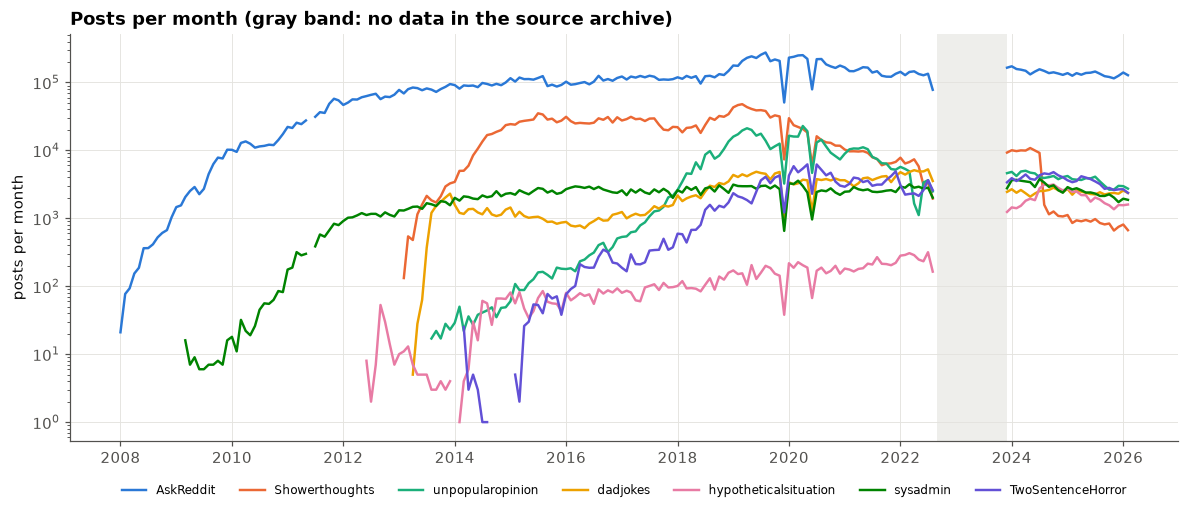

In [5]:
monthly = q("""
SELECT subreddit, date_trunc('month', created_at) AS month, count(*) AS posts
FROM posts GROUP BY 1, 2 ORDER BY 2
""")
fig, ax = plt.subplots(figsize=(13, 4.8))
shade_gap(ax)
all_months = pd.date_range(monthly.month.min(), monthly.month.max(), freq="MS")
for sub in SUBS:
    d = monthly[monthly.subreddit == sub].set_index("month").posts.reindex(all_months)  # gaps break the line
    d = d.loc[d.first_valid_index():]
    ax.plot(d.index, d.values, color=COLORS[sub], linewidth=1.6, label=sub)
ax.set_yscale("log")
ax.set_ylabel("posts per month")
ax.set_title("Posts per month (gray band: no data in the source archive)")
ax.legend(frameon=False, ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8)
monthly.pivot(index="month", columns="subreddit", values="posts").resample("YE").sum().astype(int)

In [6]:
# Months with days that have no posts at all in AskReddit (the busiest subreddit): partial months in the source
q("""
WITH d AS (
  SELECT date_trunc('month', created_at) AS month, count(DISTINCT created_at::DATE) AS days_with_posts
  FROM posts WHERE subreddit = 'AskReddit' GROUP BY 1
)
SELECT month, days_with_posts, day(last_day(month)) AS days_in_month
FROM d WHERE days_with_posts < day(last_day(month)) ORDER BY month
""")

,month,days_with_posts,days_in_month
0,2008-01-01,7,31
1,2008-02-01,26,29
2,2008-03-01,29,31
3,2018-06-01,26,30
4,2019-12-01,7,31
5,2020-06-01,11,30
6,2021-03-01,29,31
7,2022-08-01,20,31


## 3. Post types

The subreddits were chosen because they are text subreddits. Non-text posts (links, images) are dropped
from the labels and the models (`self_only=True`).

In [7]:
types = q("""
SELECT subreddit, post_type, count(*) / sum(count(*)) OVER (PARTITION BY subreddit) AS share
FROM posts GROUP BY 1, 2
""").pivot(index="subreddit", columns="post_type", values="share").fillna(0)
types

post_type,external link,gallery,image,self,video
subreddit,,,,,
AskReddit,0.002,0.000,0.000,0.998,0.000
Showerthoughts,0.001,0.000,0.000,0.999,0.000
TwoSentenceHorror,0.000,0.000,0.000,1.000,0.000
dadjokes,0.005,0.000,0.004,0.991,0.000
hypotheticalsituation,0.003,0.000,0.000,0.997,0.000
sysadmin,0.056,0.000,0.007,0.934,0.002
unpopularopinion,0.000,0.000,0.000,1.000,0.000


In [8]:
# Share of text posts by year: did a subreddit allow links or images in some years?
q("""
SELECT subreddit, year, avg((post_type = 'self')::INT) AS self_share FROM posts GROUP BY 1, 2
""").pivot(index="year", columns="subreddit", values="self_share")

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
year,,,,,,,
2008,0.866,NaN,NaN,NaN,NaN,NaN,NaN
2009,0.763,NaN,NaN,NaN,NaN,0.146,NaN
2010,0.872,NaN,NaN,NaN,NaN,0.605,NaN
2011,1.000,NaN,NaN,0.750,NaN,0.802,NaN
2012,1.000,NaN,NaN,NaN,1.000,0.814,1.000
2013,1.000,1.000,NaN,0.830,1.000,0.837,0.981
2014,0.999,1.000,1.000,1.000,1.000,0.819,1.000
2015,1.000,1.000,1.000,1.000,1.000,0.826,1.000
2016,1.000,1.000,1.000,1.000,1.000,0.836,1.000


## 4. Outcomes: score and comments

Text posts with a label. `engagement = ln(1 + score) + ln(1 + comments)`.

In [9]:
q("""
SELECT subreddit, count(*) AS posts,
       quantile_cont(score, [0.25, 0.5, 0.75, 0.9, 0.99]) AS score_quantiles,
       quantile_cont(num_comments, [0.25, 0.5, 0.75, 0.9, 0.99]) AS comment_quantiles,
       max(score) AS max_score, max(num_comments) AS max_comments
FROM eda GROUP BY 1 ORDER BY posts DESC
""")

,subreddit,posts,score_quantiles,comment_quantiles,max_score,max_comments
0,AskReddit,20132322,"[1.0, 2.0, 3.0, 5.0, 57.0]","[3.0, 7.0, 13.0, 24.0, 177.0]",202717,81376
1,Showerthoughts,2331520,"[1.0, 4.0, 10.0, 29.0, 1225.0]","[1.0, 2.0, 5.0, 10.0, 81.0]",188884,12671
2,unpopularopinion,675633,"[1.0, 7.0, 21.0, 79.0, 1759.0]","[6.0, 13.0, 28.0, 61.0, 431.0]",118301,12523
3,sysadmin,349903,"[1.0, 2.0, 6.0, 23.0, 574.0]","[3.0, 8.0, 17.0, 39.0, 285.0]",18276,4670
4,dadjokes,328639,"[3.0, 7.0, 22.0, 87.0, 3231.6199999999953]","[0.0, 1.0, 4.0, 9.0, 82.0]",70316,2182
5,TwoSentenceHorror,269565,"[6.0, 15.0, 45.0, 217.0, 4275.359999999986]","[0.0, 2.0, 5.0, 12.0, 89.0]",35919,1428
6,hypotheticalsituation,68346,"[1.0, 3.0, 16.0, 80.0, 839.0]","[4.0, 12.0, 40.0, 143.0, 918.0]",16339,6877


Spearman correlation of score and comments, by subreddit:
subreddit
unpopularopinion        0.353
Showerthoughts          0.416
AskReddit               0.432
sysadmin                0.497
dadjokes                0.557
hypotheticalsituation   0.598
TwoSentenceHorror       0.629


Text(0.01, 0.98, 'Distribution of engagement (log y)')

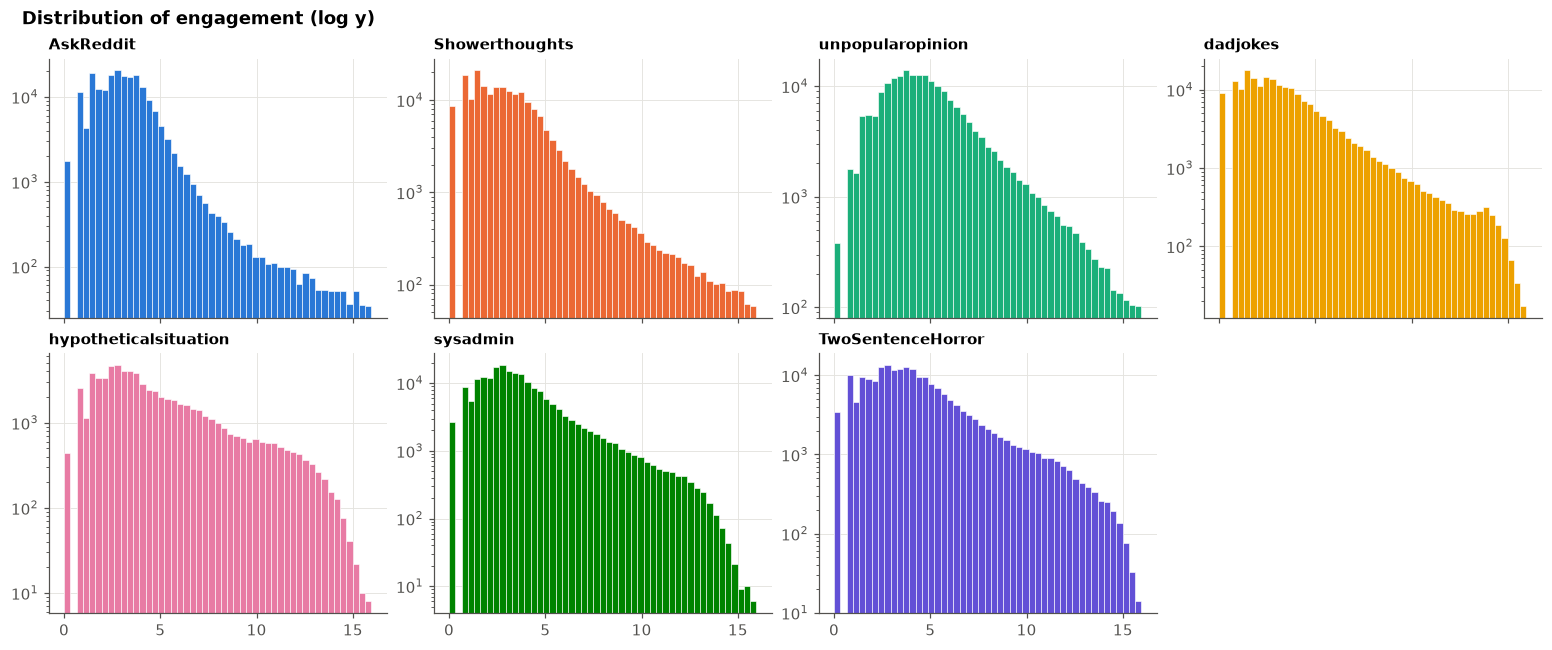

In [10]:
s = q("SELECT subreddit, score, num_comments, engagement FROM eda_sample")
spearman = s.groupby("subreddit")[["score", "num_comments"]].corr(method="spearman").xs("score", level=1)["num_comments"]
print("Spearman correlation of score and comments, by subreddit:")
print(spearman.round(3).sort_values().to_string())

fig, axes = panels(sharex=True)
bins = np.linspace(0, s.engagement.quantile(0.999), 50)
for ax, sub in zip(axes, SUBS):
    ax.hist(s.loc[s.subreddit == sub, "engagement"], bins=bins, color=COLORS[sub], edgecolor="white", linewidth=0.4)
    ax.set_title(sub, fontsize=10)
    ax.set_yscale("log")
fig.suptitle("Distribution of engagement (log y)", x=0.01, ha="left", fontweight="bold")

## 5. Score maturity by year

`score` and `num_comments` are values at archival time. In older archives, posts were sometimes collected
soon after they were created, so their values are lower than their final values. If a year has a very
high share of posts with score ≤ 1, its scores may be immature. Reddit's vote fuzzing and the size of each
subreddit also change over the years. Per-period labels absorb a general level change, but not a change in
**which** posts get recorded late.

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
year,,,,,,,
2008,2.000,NaN,NaN,NaN,NaN,NaN,NaN
2009,3.000,NaN,NaN,NaN,NaN,NaN,NaN
2010,2.000,NaN,NaN,NaN,NaN,5.000,NaN
2011,1.000,NaN,NaN,NaN,NaN,4.000,NaN
2012,1.000,NaN,NaN,NaN,NaN,3.000,NaN
2013,1.000,7.000,NaN,8.000,NaN,4.000,NaN
2014,1.000,1.000,NaN,5.000,14.000,3.000,8.000
2015,1.000,1.000,9.000,5.000,13.000,2.000,9.000
2016,2.000,2.000,11.000,7.000,9.000,3.000,9.000


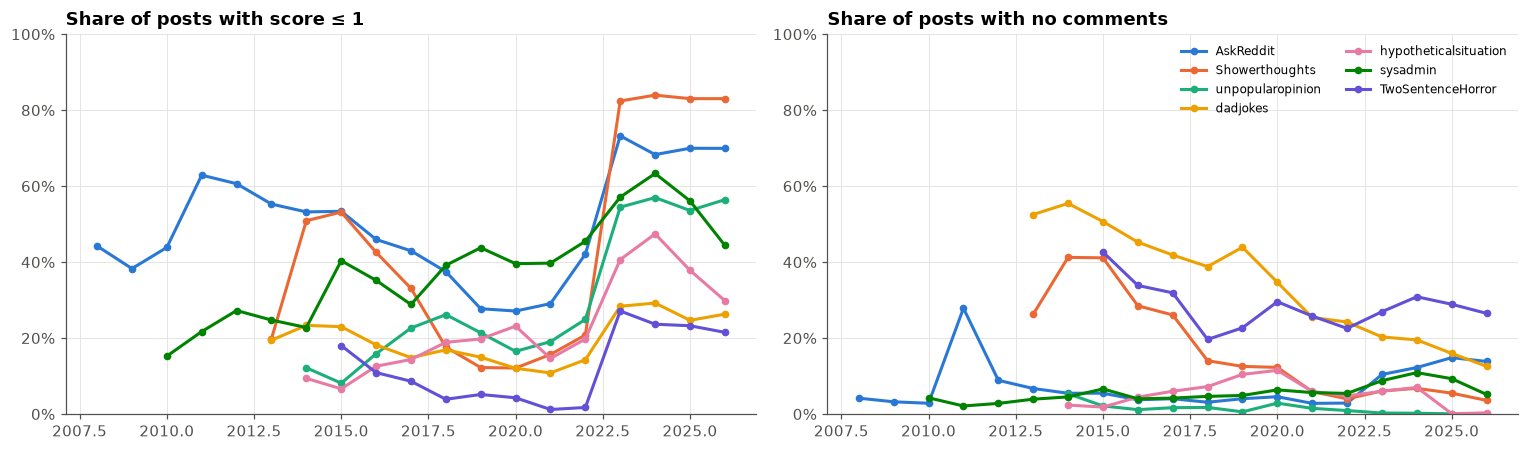

In [11]:
by_year = q("""
SELECT subreddit, year, count(*) AS posts, median(score) AS median_score, median(num_comments) AS median_comments,
       avg((score <= 1)::INT) AS score_le_1, avg((num_comments = 0)::INT) AS zero_comments
FROM eda GROUP BY 1, 2 ORDER BY 2
""")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col, title in [(axes[0], "score_le_1", "Share of posts with score ≤ 1"),
                       (axes[1], "zero_comments", "Share of posts with no comments")]:
    for sub in SUBS:
        d = by_year[by_year.subreddit == sub]
        ax.plot(d.year, d[col], color=COLORS[sub], marker="o", markersize=4, label=sub)
    ax.set_title(title); pct_axis(ax); ax.set_ylim(0, 1)
axes[1].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
by_year.pivot(index="year", columns="subreddit", values="median_score")

In [12]:
by_year.pivot(index="year", columns="subreddit", values="median_comments")

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
year,,,,,,,
2008,8.000,NaN,NaN,NaN,NaN,NaN,NaN
2009,12.000,NaN,NaN,NaN,NaN,NaN,NaN
2010,11.000,NaN,NaN,NaN,NaN,10.000,NaN
2011,6.000,NaN,NaN,NaN,NaN,11.000,NaN
2012,8.000,NaN,NaN,NaN,NaN,11.000,NaN
2013,7.000,2.000,NaN,0.000,NaN,9.000,NaN
2014,6.000,1.000,NaN,0.000,13.000,9.000,6.000
2015,6.000,1.000,1.000,0.000,9.000,9.000,10.000
2016,7.000,2.000,1.000,1.000,5.000,8.000,12.000


## 6. Threshold drift: why the label is per time period

The success threshold (90th percentile of engagement) of each subreddit in each quarter. A threshold fixed
over all years would label almost every post in a busy era as a success, and almost none in a quiet era.

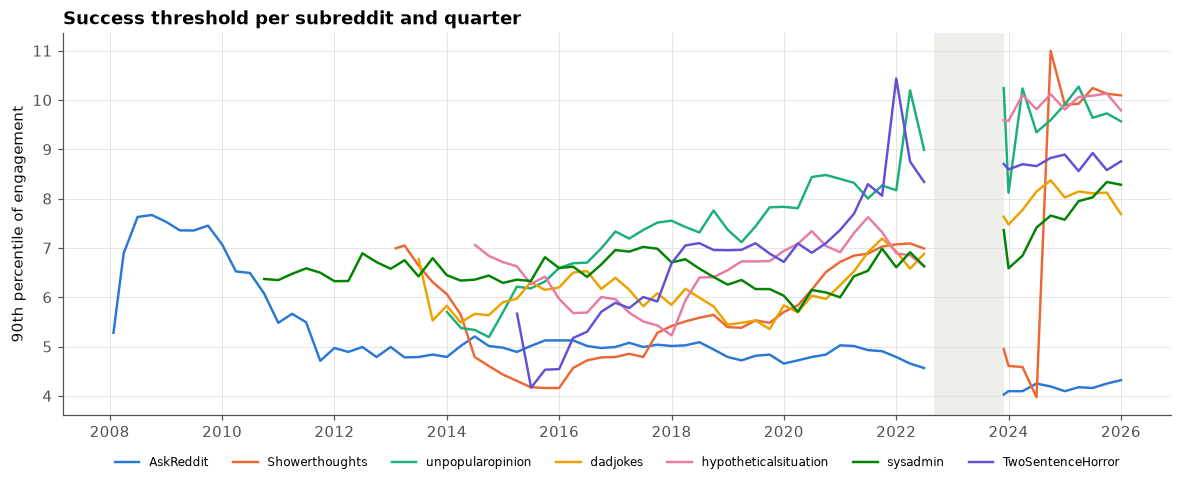

In [13]:
thr = q("""
SELECT t.subreddit, t.period, t.threshold, t.period_posts, min(e.created_at) AS start
FROM thresholds t JOIN eda e USING (subreddit, period) GROUP BY ALL ORDER BY start
""")
fig, ax = plt.subplots(figsize=(13, 4.5))
shade_gap(ax)
for sub in SUBS:
    d = thr[thr.subreddit == sub].set_index("start").threshold
    d = d.reindex(d.index.union(d.index[:-1][np.diff(d.index) > pd.Timedelta(days=100)] + pd.Timedelta(days=95)))
    ax.plot(d.index, d.values, color=COLORS[sub], linewidth=1.6, label=sub)  # NaN after a gap breaks the line
ax.set_ylabel("90th percentile of engagement")
ax.set_title("Success threshold per subreddit and quarter")
ax.legend(frameon=False, ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8)

In [14]:
# Text posts that lose their label because their subreddit-quarter has too few posts
q(f"""
SELECT b.subreddit, count(*) AS text_posts, count(t.subreddit) AS labeled_posts,
       1 - count(t.subreddit) / count(*) AS dropped_share
FROM label_base b LEFT JOIN thresholds t USING (subreddit, period) GROUP BY 1 ORDER BY 2 DESC
""")

,subreddit,text_posts,labeled_posts,dropped_share
0,AskReddit,20132322,20132322,0.000
1,Showerthoughts,2331520,2331520,0.000
2,unpopularopinion,675739,675633,0.000
3,sysadmin,350063,349903,0.000
4,dadjokes,328737,328639,0.000
5,TwoSentenceHorror,269613,269565,0.000
6,hypotheticalsituation,68597,68346,0.004


## 7. Label base rates

Ties at the threshold make the success rate a bit lower than 10% in some periods (many posts share the same
small score and comment counts).

In [15]:
q("""
WITH p AS (SELECT subreddit, period, avg(label) AS rate, count(*) AS posts FROM eda GROUP BY 1, 2)
SELECT subreddit, sum(posts) AS posts, sum(rate * posts) / sum(posts) AS success_rate,
       count(*) AS periods, min(rate) AS min_period_rate, median(rate) AS median_period_rate, max(rate) AS max_period_rate
FROM p GROUP BY 1 ORDER BY posts DESC
""")

,subreddit,posts,success_rate,periods,min_period_rate,median_period_rate,max_period_rate
0,AskReddit,"20,132,322.000",0.099,69,0.095,0.100,0.100
1,Showerthoughts,"2,331,520.000",0.100,49,0.099,0.100,0.101
2,unpopularopinion,"675,633.000",0.100,45,0.099,0.100,0.106
3,sysadmin,"349,903.000",0.100,58,0.099,0.100,0.104
4,dadjokes,"328,639.000",0.100,47,0.099,0.100,0.100
5,TwoSentenceHorror,"269,565.000",0.100,40,0.097,0.100,0.103
6,hypotheticalsituation,"68,346.000",0.100,43,0.096,0.100,0.105


## 8. Timing (local time, America/New_York)

The proposal's main question. Volumes are real activity now, so "when do people post" and "when do posts
succeed" can be compared directly.

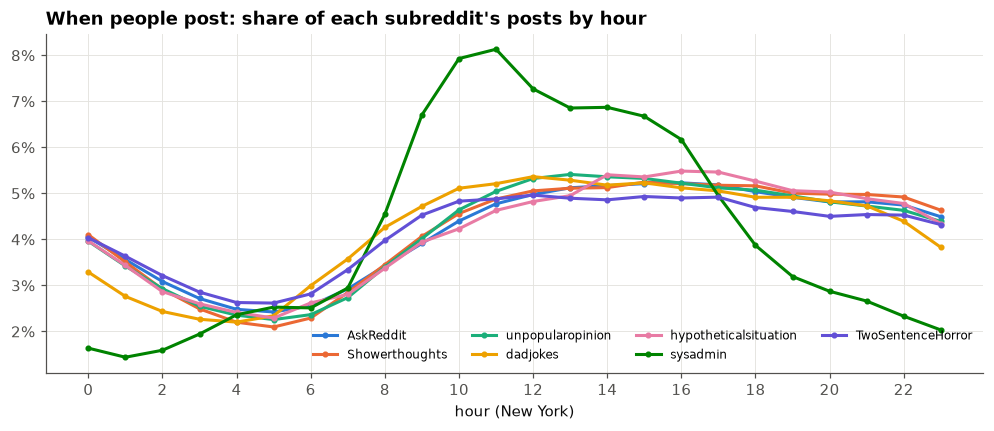

In [16]:
hourly = q("""
SELECT subreddit, local_hour, count(*) AS posts, avg(label) AS success_rate,
       count(*) / sum(count(*)) OVER (PARTITION BY subreddit) AS volume_share
FROM eda GROUP BY 1, 2 ORDER BY 2
""")
sub_rate = q("SELECT subreddit, avg(label) AS rate FROM eda GROUP BY 1").set_index("subreddit").rate

fig, ax = plt.subplots(figsize=(11, 4))
for sub in SUBS:
    d = hourly[hourly.subreddit == sub]
    ax.plot(d.local_hour, d.volume_share, color=COLORS[sub], marker="o", markersize=3, label=sub)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour (New York)"); pct_axis(ax)
ax.set_title("When people post: share of each subreddit's posts by hour")
ax.legend(frameon=False, ncol=4, fontsize=8)

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
local_hour,,,,,,,
0,0.110,0.086,0.070,0.080,0.064,0.103,0.081
1,0.113,0.090,0.071,0.072,0.068,0.098,0.084
2,0.116,0.092,0.071,0.082,0.067,0.092,0.084
3,0.118,0.098,0.076,0.088,0.065,0.086,0.089
4,0.117,0.108,0.087,0.102,0.064,0.098,0.091
5,0.118,0.120,0.108,0.134,0.086,0.103,0.116
6,0.121,0.134,0.131,0.165,0.086,0.124,0.128
7,0.116,0.139,0.142,0.165,0.108,0.145,0.134
8,0.110,0.136,0.150,0.146,0.121,0.154,0.136


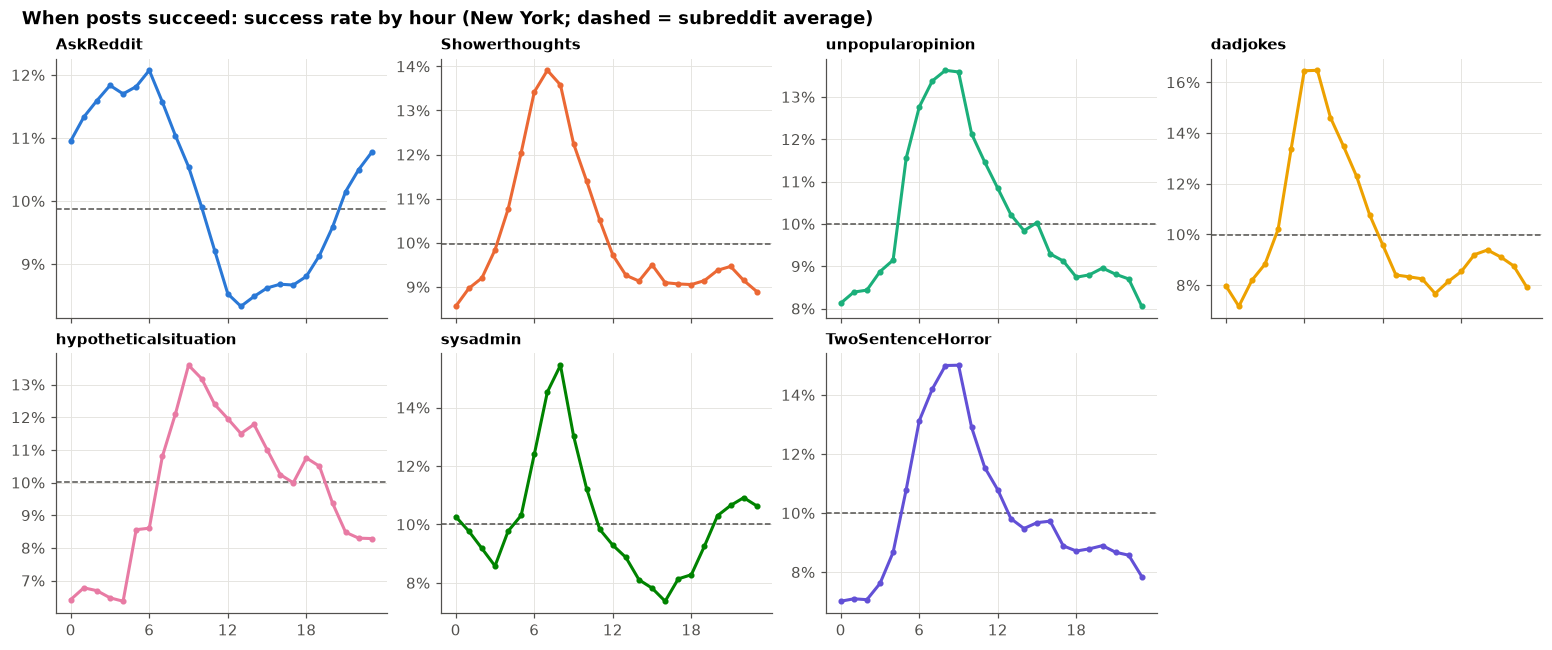

In [17]:
fig, axes = panels(sharex=True)
for ax, sub in zip(axes, SUBS):
    d = hourly[hourly.subreddit == sub]
    ax.axhline(sub_rate[sub], color=td.MUTED, linewidth=1, linestyle="--")
    ax.plot(d.local_hour, d.success_rate, color=COLORS[sub], marker="o", markersize=3)
    ax.set_title(sub, fontsize=10); pct_axis(ax); ax.set_xticks(range(0, 24, 6))
fig.suptitle("When posts succeed: success rate by hour (New York; dashed = subreddit average)",
             x=0.01, ha="left", fontweight="bold")
hourly.pivot(index="local_hour", columns="subreddit", values="success_rate")

In [18]:
# Do posts in quiet hours do better? Correlation, over the 24 hours, of posting volume and success rate
hourly.groupby("subreddit")[["volume_share", "success_rate"]].corr(method="spearman").xs("volume_share", level=1)[
    ["success_rate"]].rename(columns={"success_rate": "spearman(volume, success) over hours"})

,"spearman(volume, success) over hours"
subreddit,
AskReddit,-0.947
Showerthoughts,-0.530
TwoSentenceHorror,0.201
dadjokes,-0.126
hypotheticalsituation,0.354
sysadmin,-0.148
unpopularopinion,-0.046


### Weekday × hour heatmaps

Success rate in each weekday × hour cell divided by the subreddit's average rate (1 = average; blue above,
orange below). Cells with fewer than 30 posts are blank.

Text(0.01, 0.98, 'Success by weekday and hour (New York)')

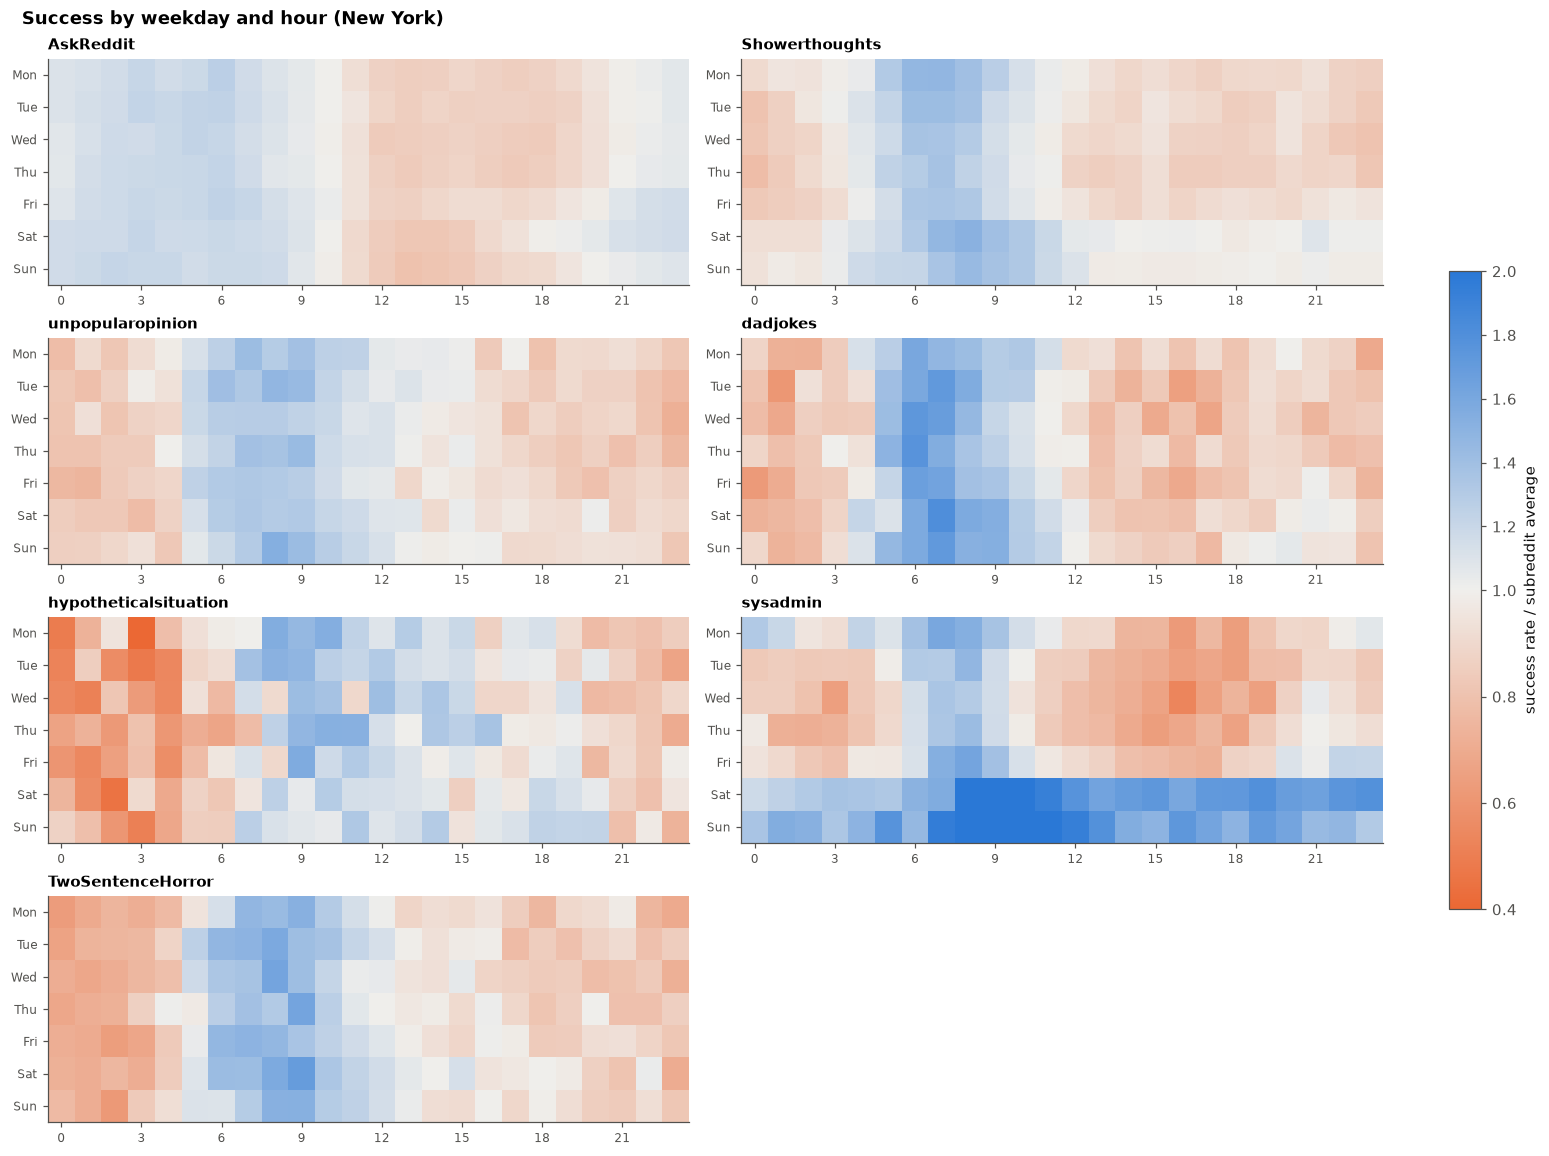

In [19]:
cells = q("""
SELECT subreddit, local_dow, local_hour, count(*) AS posts, avg(label) AS rate FROM eda GROUP BY 1, 2, 3
""")
cells["lift"] = cells.rate / cells.subreddit.map(sub_rate)
cells.loc[cells.posts < 30, "lift"] = np.nan
fig, axes = panels(ncols=2, height=2.6)
norm = TwoSlopeNorm(vcenter=1.0, vmin=0.4, vmax=2.0)
for ax, sub in zip(axes, SUBS):
    m = cells[cells.subreddit == sub].pivot(index="local_dow", columns="local_hour", values="lift")
    m = m.reindex(index=range(1, 8), columns=range(24))
    im = ax.imshow(m.to_numpy(dtype=float), cmap=DIVERGING, norm=norm, aspect="auto")
    ax.set_yticks(range(7), DOW, fontsize=8); ax.set_xticks(range(0, 24, 3), range(0, 24, 3), fontsize=8)
    ax.set_title(sub, fontsize=10); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.6, label="success rate / subreddit average")
fig.suptitle("Success by weekday and hour (New York)", x=0.01, ha="left", fontweight="bold")

In [20]:
# Best and worst weekday x hour cells per subreddit (cells with at least 100 posts)
c = cells[cells.posts >= 100].assign(day=lambda d: d.local_dow.map(lambda i: DOW[i - 1]))
best = c.sort_values("lift", ascending=False).groupby("subreddit").head(3)
worst = c.sort_values("lift").groupby("subreddit").head(3)
pd.concat([best.assign(kind="best"), worst.assign(kind="worst")]).sort_values(["subreddit", "kind", "lift"])[
    ["subreddit", "kind", "day", "local_hour", "posts", "rate", "lift"]]

,subreddit,kind,day,local_hour,posts,rate,lift
86,AskReddit,best,Tue,6,75695,0.122,1.235
167,AskReddit,best,Fri,6,74368,0.123,1.241
87,AskReddit,best,Mon,6,74067,0.125,1.262
745,AskReddit,worst,Sun,13,139964,0.079,0.801
2,AskReddit,worst,Sun,14,142904,0.081,0.817
10,AskReddit,worst,Sat,14,134677,0.081,0.823
1054,Showerthoughts,best,Mon,6,7549,0.146,1.464
820,Showerthoughts,best,Mon,7,9391,0.147,1.471
180,Showerthoughts,best,Sat,8,9671,0.150,1.509
470,Showerthoughts,worst,Thu,0,13884,0.078,0.781


subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
local_dow,,,,,,,
1,0.098,0.099,0.096,0.100,0.102,0.098,0.101
2,0.098,0.098,0.102,0.098,0.100,0.088,0.101
3,0.097,0.095,0.097,0.096,0.098,0.085,0.098
4,0.097,0.094,0.099,0.099,0.103,0.088,0.099
5,0.101,0.098,0.100,0.098,0.098,0.101,0.097
6,0.102,0.108,0.105,0.104,0.098,0.170,0.101
7,0.099,0.106,0.101,0.105,0.102,0.172,0.102


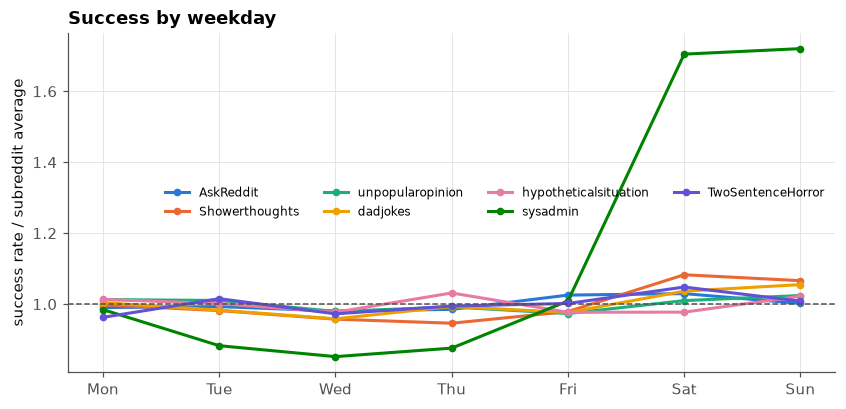

In [21]:
dow = q("SELECT subreddit, local_dow, avg(label) AS success_rate, count(*) AS posts FROM eda GROUP BY 1, 2 ORDER BY 2")
fig, ax = plt.subplots(figsize=(9, 4))
for sub in SUBS:
    d = dow[dow.subreddit == sub]
    ax.plot([DOW[i - 1] for i in d.local_dow], d.success_rate / sub_rate[sub], color=COLORS[sub], marker="o",
            markersize=4, label=sub)
ax.axhline(1, color=td.MUTED, linewidth=1, linestyle="--")
ax.set_ylabel("success rate / subreddit average"); ax.set_title("Success by weekday")
ax.legend(frameon=False, ncol=4, fontsize=8)
dow.pivot(index="local_dow", columns="subreddit", values="success_rate")

In [22]:
# Month of year. Labels are relative to the quarter, so this only shows differences between months of
# the same quarter (for example, December vs. October).
q("SELECT subreddit, local_month, avg(label) AS success_rate FROM eda GROUP BY 1, 2").pivot(
    index="local_month", columns="subreddit", values="success_rate")

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
local_month,,,,,,,
1,0.103,0.101,0.095,0.098,0.101,0.096,0.104
2,0.097,0.098,0.102,0.100,0.099,0.100,0.101
3,0.094,0.100,0.104,0.102,0.100,0.104,0.095
4,0.096,0.096,0.095,0.100,0.100,0.103,0.097
5,0.098,0.100,0.103,0.100,0.106,0.100,0.104
6,0.102,0.103,0.102,0.099,0.095,0.097,0.100
7,0.101,0.099,0.100,0.098,0.092,0.101,0.096
8,0.098,0.102,0.101,0.100,0.103,0.100,0.099
9,0.099,0.098,0.099,0.102,0.105,0.099,0.107


## 9. Competition: how crowded is /new?

`posts_prev_hour` counts posts in the same subreddit in the hour before. A crowded /new pushes a post down
faster, but busy hours also have more readers. This is confounded with the hour of day.

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
decile,,,,,,,
1,68.905,8.178,0.608,0.476,0.000,0.378,2.290
2,119.771,17.195,2.031,1.486,0.012,1.397,5.395
3,146.561,24.341,3.000,2.257,1.000,2.335,7.925
4,167.021,30.979,3.926,3.000,1.435,3.328,10.550
5,185.101,36.591,4.707,3.961,2.000,4.399,13.479
6,202.761,41.598,5.512,4.723,2.851,5.520,16.705
7,222.276,46.486,6.434,5.606,3.367,6.693,20.319
8,250.330,51.854,7.522,6.663,4.207,8.151,24.438
9,304.630,59.029,9.085,8.246,5.377,9.788,29.626


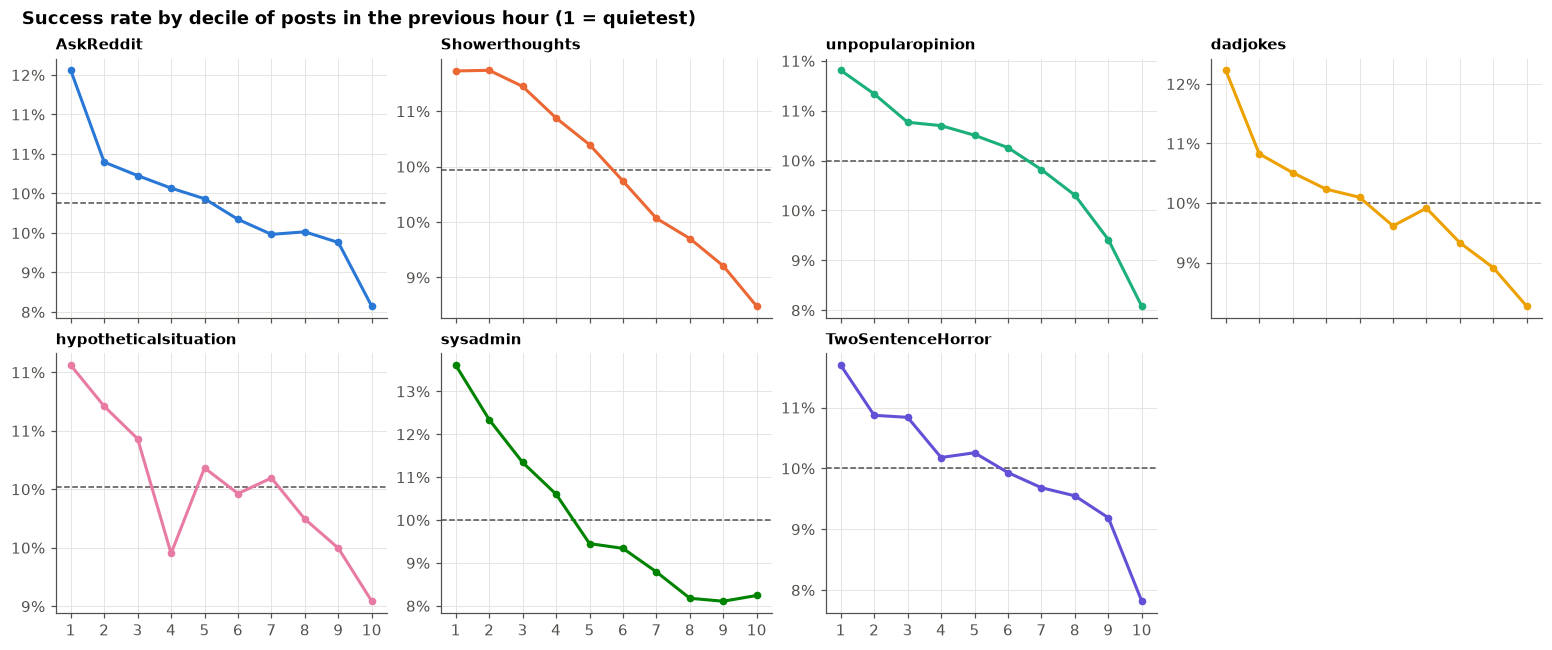

In [23]:
comp = q("""
WITH d AS (SELECT subreddit, posts_prev_hour, label,
                  ntile(10) OVER (PARTITION BY subreddit ORDER BY posts_prev_hour) AS decile FROM eda)
SELECT subreddit, decile, avg(posts_prev_hour) AS mean_prev_hour, avg(label) AS success_rate, count(*) AS posts
FROM d GROUP BY 1, 2 ORDER BY 2
""")
fig, axes = panels(sharex=True)
for ax, sub in zip(axes, SUBS):
    d = comp[comp.subreddit == sub]
    ax.axhline(sub_rate[sub], color=td.MUTED, linewidth=1, linestyle="--")
    ax.plot(d.decile, d.success_rate, color=COLORS[sub], marker="o", markersize=4)
    ax.set_title(sub, fontsize=10); pct_axis(ax); ax.set_xticks(range(1, 11))
fig.suptitle("Success rate by decile of posts in the previous hour (1 = quietest)", x=0.01, ha="left",
             fontweight="bold")
comp.pivot(index="decile", columns="subreddit", values="mean_prev_hour")

## 10. Content structure

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
decile (max chars),,,,,,,
1,37,42,35,25,28,21,27
2,45,54,47,31,43,28,34
3,51,64,57,36,55,33,41
4,58,73,66,40,67,38,48
5,65,83,74,45,79,44,55
6,73,93,84,50,93,50,63
7,83,105,95,57,110,57,73
8,96,121,109,66,134,67,87
9,118,146,130,82,178,83,110


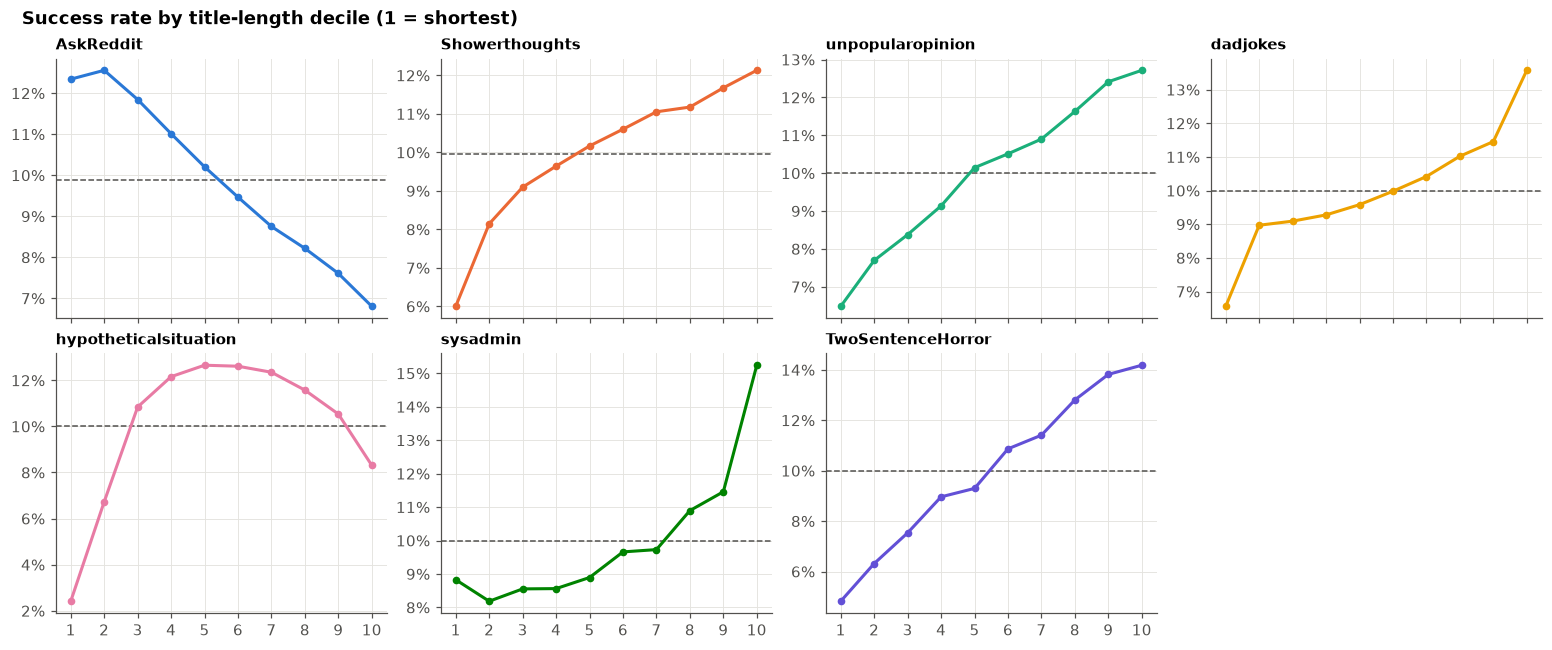

In [24]:
tl = q("""
WITH d AS (SELECT subreddit, title_length, label,
                  ntile(10) OVER (PARTITION BY subreddit ORDER BY title_length) AS decile FROM eda)
SELECT subreddit, decile, min(title_length) AS min_chars, max(title_length) AS max_chars, avg(label) AS success_rate
FROM d GROUP BY 1, 2 ORDER BY 2
""")
fig, axes = panels(sharex=True)
for ax, sub in zip(axes, SUBS):
    d = tl[tl.subreddit == sub]
    ax.axhline(sub_rate[sub], color=td.MUTED, linewidth=1, linestyle="--")
    ax.plot(d.decile, d.success_rate, color=COLORS[sub], marker="o", markersize=4)
    ax.set_title(sub, fontsize=10); pct_axis(ax); ax.set_xticks(range(1, 11))
fig.suptitle("Success rate by title-length decile (1 = shortest)", x=0.01, ha="left", fontweight="bold")
tl.pivot(index="decile", columns="subreddit", values="max_chars").rename_axis("decile (max chars)")

In [25]:
# For each binary feature: share of posts that have it, and its success rate relative to posts without it
FLAGS = ["has_body", "title_has_question", "title_has_number", "title_all_caps", "body_has_url",
         "has_link_flair", "has_author_flair"]
rows = []
for f in FLAGS:
    d = q(f"""
    SELECT subreddit, avg({f}) AS share, avg(label) FILTER ({f} = 1) AS rate_with,
           avg(label) FILTER ({f} = 0) AS rate_without
    FROM eda GROUP BY 1
    """)
    d["feature"] = f
    rows.append(d)
flags = pd.concat(rows)
flags["lift"] = flags.rate_with / flags.rate_without
print("Share of posts with the feature:")
display(flags.pivot(index="feature", columns="subreddit", values="share"))
print("Success rate with the feature / without it (blank = no posts with it):")
flags.pivot(index="feature", columns="subreddit", values="lift")

Share of posts with the feature:


subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
feature,,,,,,,
body_has_url,0.008,0.004,0.001,0.015,0.013,0.148,0.025
has_author_flair,0.003,0.014,0.050,0.003,0.001,0.185,0.039
has_body,0.109,0.140,0.974,0.978,0.834,0.985,0.997
has_link_flair,0.032,0.016,0.001,0.001,0.095,0.252,0.003
title_all_caps,0.001,0.000,0.002,0.002,0.001,0.002,0.001
title_has_number,0.066,0.087,0.081,0.053,0.346,0.216,0.055
title_has_question,0.975,0.086,0.039,0.401,0.433,0.337,0.006


Success rate with the feature / without it (blank = no posts with it):


subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
feature,,,,,,,
body_has_url,0.712,0.604,1.097,0.750,0.668,1.538,0.836
has_author_flair,1.074,1.189,1.510,1.119,1.567,1.740,1.053
has_body,0.943,0.690,3.339,0.961,1.400,1.120,0.819
has_link_flair,0.952,1.871,3.645,1.162,1.476,1.578,6.105
title_all_caps,0.038,0.150,0.780,0.791,0.312,0.863,0.659
title_has_number,1.094,1.335,1.236,1.789,3.303,0.787,0.890
title_has_question,3.326,0.715,1.236,0.806,0.953,1.171,0.660


In [26]:
# Body length: empty, short, and long bodies (characters before any EDIT marker)
q("""
SELECT subreddit,
       CASE WHEN body_length = 0 THEN '0 none' WHEN body_length < 200 THEN '1 <200' WHEN body_length < 1000 THEN '2 200-999'
            WHEN body_length < 3000 THEN '3 1k-3k' ELSE '4 3k+' END AS body,
       avg(label) AS success_rate
FROM eda GROUP BY 1, 2
""").pivot(index="body", columns="subreddit", values="success_rate")

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
body,,,,,,,
0 none,0.099,0.104,0.031,0.104,0.075,0.089,0.122
1 <200,0.104,0.076,0.102,0.099,0.082,0.136,0.086
2 200-999,0.079,0.054,0.087,0.114,0.119,0.086,0.101
3 1k-3k,0.098,0.044,0.160,0.159,0.098,0.117,0.103
4 3k+,0.107,0.048,0.091,0.176,0.056,0.237,0.090


In [27]:
# The most successful titles in the latest full year, to see what success looks like in each subreddit
q("""
SELECT subreddit, title, score, num_comments FROM eda WHERE year = 2025
QUALIFY row_number() OVER (PARTITION BY subreddit ORDER BY engagement DESC) <= 3
ORDER BY subreddit, engagement DESC
""")

,subreddit,title,score,num_comments
0,AskReddit,Why do you think President Trump ordered all US Flags at half staff for the death of a Political...,114515,8721
1,AskReddit,ABC just pulled Jimmy Kimmel Live “indefinitely” due to comments he made about Charlie Kirk. Wha...,60584,14597
2,AskReddit,"Americans, How do you feel about the fact that the stock market has lost $2 trillion in value to...",44822,17500
3,Showerthoughts,"Men's public restrooms are laid out all wrong. It should be urinal, stall, urinal, stall, urinal...",21438,1165
4,Showerthoughts,Aliens wouldn't invade earth to enslave humanity or for Earth's resources. Aliens can travel acr...,14037,1754
5,Showerthoughts,It's crazy how the previous generations were so addicted to cigarettes that they had inbuilt lig...,16183,1315
6,TwoSentenceHorror,"“Sorry, I forgot my room number, my wife Anna booked the room,” said the man calling.",9842,187
7,TwoSentenceHorror,"My coworker never struck me as very misogynistic, so I was surprised when he told me to smile fo...",9227,197
8,TwoSentenceHorror,"My heart nearly stopped when the day before my daughter turned sixteen she said ""Mum, Dad, I've ...",7737,222
9,dadjokes,Asked my son what he learned in school today. He said “Gay men like ynoS. Lesbians favour ahamaY...,31455,479


## 11. Edit notes leak the outcome

Authors often edit a post **after** it does well ("EDIT: thanks for the gold", "Update: wow, this blew up").
The archived `selftext` includes those edits, so a model that reads the full body can learn the outcome.
`body_has_edit` flags an edit marker (`textonly_data.EDIT_RE`). The models use `body_clean`, which is cut at
the first marker. This check shows how strong the leak would be.

In [28]:
q("""
SELECT subreddit, avg(body_has_edit) AS share_with_edit,
       avg(label) FILTER (body_has_edit = 1) AS success_with_edit,
       avg(label) FILTER (body_has_edit = 0) AS success_without_edit,
       success_with_edit / success_without_edit AS lift
FROM eda GROUP BY 1 ORDER BY lift DESC
""")

,subreddit,share_with_edit,success_with_edit,success_without_edit,lift
0,dadjokes,0.004,0.339,0.099,3.422
1,unpopularopinion,0.049,0.224,0.094,2.396
2,Showerthoughts,0.005,0.231,0.099,2.333
3,AskReddit,0.007,0.223,0.098,2.281
4,TwoSentenceHorror,0.001,0.213,0.100,2.131
5,hypotheticalsituation,0.006,0.210,0.099,2.110
6,sysadmin,0.072,0.194,0.093,2.091


## 12. Reposts

`title_prev_count` counts earlier posts in the same subreddit with the same normalized title (lowercase,
letters and digits only). dadjokes is known for repeated jokes.

In [29]:
q("""
SELECT subreddit, avg((title_prev_count > 0)::INT) AS repost_share,
       avg(label) FILTER (title_prev_count = 0) AS success_first,
       avg(label) FILTER (title_prev_count > 0) AS success_repost
FROM eda GROUP BY 1 ORDER BY repost_share DESC
""")

,subreddit,repost_share,success_first,success_repost
0,dadjokes,0.122,0.092,0.156
1,AskReddit,0.112,0.091,0.161
2,unpopularopinion,0.029,0.100,0.109
3,hypotheticalsituation,0.022,0.102,0.033
4,sysadmin,0.019,0.100,0.104
5,TwoSentenceHorror,0.017,0.101,0.066
6,Showerthoughts,0.013,0.099,0.176


In [30]:
# The most repeated titles per subreddit
q("""
SELECT subreddit, lower(title) AS title, count(*) AS times, avg(label) AS success_rate
FROM eda GROUP BY 1, 2
QUALIFY row_number() OVER (PARTITION BY subreddit ORDER BY count(*) DESC) <= 3
ORDER BY subreddit, times DESC
""")

,subreddit,title,times,success_rate
0,AskReddit,what makes you happy?,2875,0.233
1,AskReddit,how was your day?,2539,0.161
2,AskReddit,what keeps you up at night?,2220,0.326
3,Showerthoughts,the brain named itself.,88,0.034
4,Showerthoughts,the brain named itself,87,0.046
5,Showerthoughts,test-post.,62,0.000
6,TwoSentenceHorror,"[oct2020] this halloween, the pumpkin king knocked upon my door and said “trick or treat!”",43,0.023
7,TwoSentenceHorror,please upvote me,24,0.000
8,TwoSentenceHorror,.,23,0.043
9,dadjokes,when does a joke become a dad joke?,224,0.205


## 13. Megathreads and bots

Scheduled community threads (for example sysadmin's "Moronic Monday", mostly posted by AutoModerator) get
many comments automatically. `add_labels` drops them (`textonly_data.MEGATHREAD_SQL`), so they are not in
`eda`. This table counts them in all text posts.

In [31]:
q("""
SELECT subreddit, count(*) FILTER (is_megathread = 1) AS megathreads,
       avg(is_megathread) AS share,
       median(num_comments) FILTER (is_megathread = 1) AS median_comments_megathread,
       median(num_comments) FILTER (is_megathread = 0) AS median_comments_other,
       any_value(title) FILTER (is_megathread = 1) AS example
FROM posts WHERE post_type = 'self' GROUP BY 1 ORDER BY megathreads DESC
""")

,subreddit,megathreads,share,median_comments_megathread,median_comments_other,example
0,sysadmin,1528,0.004,63.500,8.000,"Thickheaded Thursday Feb 21, 2013"
1,unpopularopinion,388,0.001,13.000,13.000,Megathreads are not good
2,AskReddit,369,0.000,5.000,7.000,[Megathread] What would you like to ask Reddit about the holidays? megathread
3,Showerthoughts,13,0.000,0.000,2.000,"Happy Cakeday, r/Showerthoughts! Today you're 10"
4,dadjokes,1,0.000,4.000,1.000,[MEGATHREAD] Dad joke
5,hypotheticalsituation,0,0.000,NaN,12.000,NaN
6,TwoSentenceHorror,0,0.000,NaN,2.000,NaN


## 14. Authors

In [32]:
q("""
WITH a AS (SELECT subreddit, author, count(*) AS posts FROM eda GROUP BY 1, 2)
SELECT subreddit, count(*) AS authors, avg(posts) AS mean_posts,
       quantile_cont(posts, [0.5, 0.9, 0.99]) AS posts_quantiles, max(posts) AS max_posts
FROM a GROUP BY 1 ORDER BY authors DESC
""")

,subreddit,authors,mean_posts,posts_quantiles,max_posts
0,AskReddit,5216623,3.859,"[1.0, 7.0, 40.0]",5172
1,Showerthoughts,967753,2.409,"[1.0, 4.0, 19.0]",2110
2,unpopularopinion,357562,1.890,"[1.0, 3.0, 13.0]",592
3,dadjokes,136904,2.401,"[1.0, 3.0, 20.0]",3414
4,sysadmin,128349,2.726,"[1.0, 5.0, 25.0]",945
5,TwoSentenceHorror,86924,3.101,"[1.0, 5.0, 29.0]",1503
6,hypotheticalsituation,24549,2.784,"[1.0, 4.0, 29.0]",1357


In [33]:
# Heaviest posters per subreddit (bots and regulars)
q("""
SELECT subreddit, author, count(*) AS posts, avg(label) AS success_rate, min(year) AS first_year, max(year) AS last_year
FROM eda GROUP BY 1, 2
QUALIFY row_number() OVER (PARTITION BY subreddit ORDER BY count(*) DESC) <= 5
ORDER BY subreddit, posts DESC
""")

,subreddit,author,posts,success_rate,first_year,last_year
0,AskReddit,Shinespark7,5172,0.094,2018,2020
1,AskReddit,dirtymoney,4553,0.097,2008,2026
2,AskReddit,KillerQ97,4003,0.096,2018,2021
3,AskReddit,Kingflares,3666,0.046,2016,2022
4,AskReddit,Kohrack,3577,0.061,2020,2022
5,Showerthoughts,Breeze_in_the_Trees,2110,0.063,2015,2025
6,Showerthoughts,Animeking1108,1591,0.107,2018,2024
7,Showerthoughts,Seedpound,1227,0.018,2016,2026
8,Showerthoughts,VerbotenPublish,1212,0.044,2018,2022
9,Showerthoughts,digitalenabler,1164,0.019,2019,2019


In [34]:
# Do authors with earlier posts in the subreddit do better? (Only earlier posts count, so no leak.)
q("""
SELECT subreddit,
       CASE WHEN author_prev_posts = 0 THEN '0 first post' WHEN author_prev_posts < 3 THEN '1 1-2'
            WHEN author_prev_posts < 10 THEN '2 3-9' ELSE '3 10+' END AS earlier_posts,
       avg(label) AS success_rate
FROM eda GROUP BY 1, 2
""").pivot(index="earlier_posts", columns="subreddit", values="success_rate")

subreddit,AskReddit,Showerthoughts,TwoSentenceHorror,dadjokes,hypotheticalsituation,sysadmin,unpopularopinion
earlier_posts,,,,,,,
0 first post,0.087,0.098,0.082,0.091,0.112,0.086,0.097
1 1-2,0.096,0.102,0.090,0.096,0.105,0.099,0.105
2 3-9,0.104,0.103,0.099,0.100,0.103,0.107,0.106
3 10+,0.106,0.096,0.128,0.118,0.083,0.118,0.095


## 15. Score, comments, or engagement?

The share of posts in the top 10% (per subreddit and quarter) by one metric that are also in the top 10% by
another. Low overlap means the subreddit rewards upvotes and discussion differently.

In [35]:
q("""
WITH t AS (
  SELECT subreddit, period, quantile_cont(score_metric, 0.9) AS ts, quantile_cont(comments_metric, 0.9) AS tc,
         quantile_cont(engagement, 0.9) AS te
  FROM eda GROUP BY 1, 2
), b AS (
  SELECT subreddit, score_metric > ts AS s, comments_metric > tc AS c, engagement > te AS e
  FROM eda JOIN t USING (subreddit, period)
)
SELECT subreddit,
       avg(c::INT) FILTER (s) AS top_score_also_top_comments,
       avg(s::INT) FILTER (c) AS top_comments_also_top_score,
       avg(e::INT) FILTER (s) AS top_score_also_top_engagement,
       avg(e::INT) FILTER (c) AS top_comments_also_top_engagement
FROM b GROUP BY 1 ORDER BY 2
""")

,subreddit,top_score_also_top_comments,top_comments_also_top_score,top_score_also_top_engagement,top_comments_also_top_engagement
0,Showerthoughts,0.538,0.574,0.866,0.676
1,unpopularopinion,0.592,0.596,0.865,0.709
2,AskReddit,0.608,0.546,0.815,0.776
3,dadjokes,0.672,0.725,0.897,0.817
4,sysadmin,0.706,0.705,0.887,0.823
5,TwoSentenceHorror,0.727,0.766,0.909,0.851
6,hypotheticalsituation,0.751,0.750,0.878,0.874


## Summary

Fill in after running on the full extract. Questions to answer:

- **Data:** which years and months are complete? Do any years look immature (very high share of score ≤ 1)?
  Should training start later than the first year of each subreddit?
- **Labels:** is the per-quarter threshold stable enough? Does any subreddit need score-only or comments-only labels?
- **Timing:** which subreddits have a clear hour or weekday pattern? Do quiet hours (low competition) do better?
- **Content:** which structure features matter, and do they differ by subreddit?
- **Leaks:** how strong is the edit-note leak? (The models already cut bodies at the first marker.)
- **Reposts and authors:** do reposts and returning authors do better or worse? Are there other bots or
  scheduled threads that `MEGATHREAD_SQL` misses?